# Analiza wyników badań: Data Vault 2.0 vs model gwiazdy

Notebook odtwarza wszystkie tabele i wykresy rozdziałów 6–7 z surowych plików `bench_results/*.csv`.

| Plik | Źródło | Testy |
|---|---|---|
| `etl_runs.csv`, `etl_stages.csv` | `run_etl_benchmark.py` | T1–T7, T15–T20 |
| `query_runs.csv`, `query_checks.csv` | `run_query_benchmarks.py` | T8–T12, T19 |
| `evolution_runs.csv`, `evolution_checks.csv` | `run_evolution_test.py` | T23 |
| `complexity.csv` | `complexity.sql` (stan `base` i `after_t23`) | T21, T23 |

Konwencje: wynik = **mediana z 5 powtórzeń**, w nawiasie **rozstęp [min–max]**; P1–P4 — przekroje objętościowe.

In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

IN = Path("../bench_results")
MIN_SESSION = "etl_20261009-123633"
FIG = IN / "figures"
FIG.mkdir(parents=True, exist_ok=True)

TIERS = ["slams_1y", "mid_1y", "mid_5y", "mid_10y"]
P = {"slams_1y": "P1", "mid_1y": "P2", "mid_5y": "P3", "mid_10y": "P4"}
QUERIES = {
    "q1_fact_aggregation": "Q1 agregacja faktów", "q2_tournament_surface": "Q2 turniej × nawierzchnia",
    "q3_aces_ranking": "Q3 ranking asów", "q4_win_rate_country_surface": "Q4 kraj × nawierzchnia",
    "q5_head_to_head": "Q5 bilans H2H", "q6_rolling_form": "Q6 forma krocząca",
    "q7_point_in_time": "Q7 stan na chwilę T",
}

COL = {"DV": "#008000", "STAR": "#4a3aa7", "DMART": "#2a78d6"}   # DV = zieleń wydziałowa rgb(0, 0.5, 0)
MRK = {"DV": "o", "STAR": "s", "DMART": "^"}
HATCH = {"DV": "", "STAR": "//", "DMART": ".."}
LBL = {"DV": "Data Vault", "STAR": "Model gwiazdy", "DMART": "DV — warstwa prezentacyjna"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2a27", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.width", 200, "display.max_columns", 40)


from matplotlib.ticker import FuncFormatter

def pl(x: float, nd: int = 2) -> str:
    return f"{x:.{nd}f}".replace(".", ",")

PLFMT = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))


def med_rng(s: pd.Series, nd: int = 3) -> str:
    return f"{s.median():.{nd}f} [{s.min():.{nd}f}–{s.max():.{nd}f}]"


def savefig(fig, name: str):
    for ext in ("pdf", "png"):
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")

## 1. Wczytanie danych i kontrola jakości

Warunki poprawności pomiaru: brak błędów ładowania, brak zduplikowanych przebiegów, zgodna liczba meczów
w obu architekturach, zgodność wyników trzech wariantów każdego zapytania oraz walidacja T23.

In [25]:
etl = pd.read_csv(IN / "etl_runs.csv")
etl = etl[etl.session >= MIN_SESSION].copy()
stages = pd.read_csv(IN / "etl_stages.csv")
stages = stages[stages.run_id.isin(etl.run_id)].copy()
q = pd.read_csv(IN / "query_runs.csv")
qchk = pd.read_csv(IN / "query_checks.csv")
ev = pd.read_csv(IN / "evolution_runs.csv")
evchk = pd.read_csv(IN / "evolution_checks.csv")
cx = pd.read_csv(IN / "complexity.csv")

etl["size_arch_mb"] = np.where(etl.architecture == "DV", etl.size_dbo_mb + etl.size_dmart_mb, etl.size_star_mb)
etl["rows_arch"] = np.where(etl.architecture == "DV", etl.rows_dbo + etl.rows_dmart, etl.rows_star)

checks = {
    "przebiegi ETL bez błędów": etl.error.isna().all(),
    "unikalne run_id": not etl.run_id.duplicated().any(),
    "zgodna liczba meczów DV = Star": (etl.groupby(["scenario", "tier", "rep"]).matches.nunique() == 1).all(),
    "zgodne wyniki zapytań (84/84)": qchk.equal_to_star.all() and len(qchk) == 84,
    "T23: brak błędów i zgodny rozkład rund": evchk.errors.isna().all() and evchk.star_equals_dmart.all() and evchk.star_equals_dv.all(),
}
display(pd.Series(checks, name="wynik").to_frame())
assert all(checks.values())
display(etl.groupby(["scenario", "architecture"]).size().unstack().rename_axis(None))

,wynik
przebiegi ETL bez błędów,True
unikalne run_id,True
zgodna liczba meczów DV = Star,True
zgodne wyniki zapytań (84/84),True
T23: brak błędów i zgodny rozkład rund,True


architecture,DV,STAR
changes,15,15
chg_base,15,15
full,20,20
inc_base,5,5
incremental,5,5


## 6.1 Analiza czasu ładowania danych (T1–T3)

In [26]:
full = etl[etl.scenario == "full"]
rows = []
for tier in TIERS:
    g = full[full.tier == tier]
    dv, st = g[g.architecture == "DV"], g[g.architecture == "STAR"]
    r = dv.duration_s.median() / st.duration_s.median()
    rows.append({"przekrój": P[tier], "mecze": int(g.matches.iloc[0]),
                 "DV [s]": med_rng(dv.duration_s), "Star [s]": med_rng(st.duration_s),
                 "DV/Star": round(r, 2), "narzut DV [%]": round(100 * (r - 1), 1)})
t1 = pd.DataFrame(rows)
t1

,przekrój,mecze,DV [s],Star [s],DV/Star,narzut DV [%]
0,P1,500,0.731 [0.719–0.745],0.436 [0.389–0.776],1.68,67.7
1,P2,1817,1.624 [1.604–1.651],0.787 [0.785–0.795],2.06,106.4
2,P3,7934,6.229 [6.198–6.292],2.758 [2.742–2.787],2.26,125.9
3,P4,14376,11.312 [11.294–11.374],4.975 [4.924–5.008],2.27,127.4


**Struktura czasu (T2).** Etapy wyznaczono z różnic znaczników `exec_date` w `stg.log_table`;
odświeżanie statystyk (`ANALYZE`) jest rejestrowane jako osobny etap.

In [27]:
def layer(o: str, seq: int) -> str:
    if o.startswith("analyze_"):
        return "ANALYZE " + o.split("_", 1)[1]
    if o.startswith(("sp_truncate_", "sp_load_buffer_", "sp_load_raw_")):
        return "stg"
    if o.startswith("sp_load_star_"):
        return "star: fakty" if "_fct_" in o else "star: wymiary"
    if o.startswith(("sp_load_hub_", "sp_load_link_")) or (o == "sp_load_ref_country" and seq < 50):
        return "dbo: huby i linki"
    if o.startswith("sp_load_sat_"):
        return "dbo: satelity statusu" if o.endswith("_status") else "dbo: satelity opisowe"
    if o.startswith(("sp_load_dim_", "sp_load_fct_", "sp_load_ref_country")):
        return "dmart"
    return None

s = stages.merge(full[["run_id", "tier", "architecture"]], on="run_id")
s["dt"] = s.groupby("run_id").t_since_start_s.diff().fillna(s.t_since_start_s)
s["layer"] = [layer(o, q_) for o, q_ in zip(s.object_name, s.seq)]
per_run = s.dropna(subset=["layer"]).groupby(["tier", "architecture", "run_id", "layer"]).dt.sum()
t2 = per_run.groupby(["tier", "architecture", "layer"]).median().reset_index()
t2["udział [%]"] = (100 * t2.dt / t2.groupby(["tier", "architecture"]).dt.transform("sum")).round(1)
t2_p4 = t2[t2.tier == "mid_10y"].drop(columns="tier").rename(columns={"dt": "czas [s]"}).round(3)
t2_p4

,architecture,layer,czas [s],udział [%]
0,DV,ANALYZE dbo,3.109,27.2
1,DV,ANALYZE dmart,0.205,1.8
2,DV,ANALYZE stg,1.613,14.1
3,DV,dbo: huby i linki,0.780,6.8
4,DV,dbo: satelity opisowe,0.713,6.2
5,DV,dbo: satelity statusu,1.049,9.2
6,DV,dmart,1.601,14.0
7,DV,stg,2.370,20.7
8,STAR,ANALYZE star,0.204,4.0
9,STAR,ANALYZE stg,1.601,31.5


In [28]:
def group3(l: str) -> str:
    if l in ("stg", "ANALYZE stg"):
        return "obszar tymczasowy (wspólny, z ANALYZE)"
    if l.startswith("ANALYZE"):
        return "ANALYZE warstw hurtowni"
    return "ładowanie warstw hurtowni"

g3 = t2.assign(skladnik=t2.layer.map(group3)).groupby(["tier", "architecture", "skladnik"]).dt.sum().unstack()
g3 = g3[["obszar tymczasowy (wspólny, z ANALYZE)", "ANALYZE warstw hurtowni", "ładowanie warstw hurtowni"]]
g3["hurtownia razem"] = g3["ANALYZE warstw hurtowni"] + g3["ładowanie warstw hurtowni"]
t3 = g3.round(2).reset_index()
t3["tier"] = t3.tier.map(P)
w = t3.pivot(index="tier", columns="architecture", values="hurtownia razem")
w["DV/Star (tylko hurtownia)"] = (w.DV / w.STAR).round(2)
display(t3.sort_values(["tier", "architecture"]))
w

skladnik,tier,architecture,"obszar tymczasowy (wspólny, z ANALYZE)",ANALYZE warstw hurtowni,ładowanie warstw hurtowni,hurtownia razem
6,P1,DV,0.43,0.15,0.28,0.43
7,P1,STAR,0.48,0.01,0.09,0.10
2,P2,DV,0.74,0.40,0.60,1.00
3,P2,STAR,0.74,0.03,0.15,0.18
4,P3,DV,2.26,1.78,2.31,4.09
5,P3,STAR,2.25,0.11,0.51,0.62
0,P4,DV,3.98,3.31,4.14,7.46
1,P4,STAR,3.98,0.20,0.90,1.11


architecture,DV,STAR,DV/Star (tylko hurtownia)
tier,,,
P1,0.43,0.10,4.30
P2,1.00,0.18,5.56
P3,4.09,0.62,6.60
P4,7.46,1.11,6.72


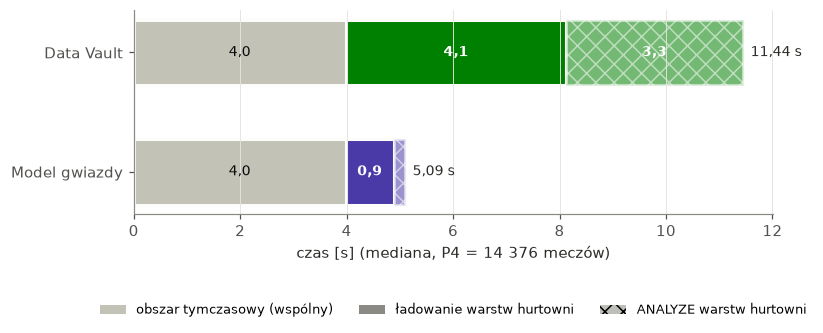

In [29]:
# Rys. 6.1 — struktura czasu pełnego ładowania, P4
comp = ["obszar tymczasowy (wspólny, z ANALYZE)", "ładowanie warstw hurtowni", "ANALYZE warstw hurtowni"]
shade = {comp[0]: "#c3c2b7", comp[1]: None, comp[2]: None}
p4 = g3.loc["mid_10y"]
fig, ax = plt.subplots(figsize=(7.5, 2.4))
for i, arch in enumerate(["STAR", "DV"]):
    left = 0
    for c in comp:
        v = p4.loc[arch, c]
        face = "#c3c2b7" if c == comp[0] else COL[arch]
        alpha = 1.0 if c != comp[2] else 0.55
        ax.barh(i, v, left=left, color=face, alpha=alpha, height=0.55, edgecolor="#fcfcfb", linewidth=2,
                hatch="xx" if c == comp[2] else None)
        if v > 0.6:
            ax.text(left + v / 2, i, pl(v, 1), ha="center", va="center", fontsize=9,
                    color="#0b0b0b" if c == comp[0] else "#ffffff", fontweight="bold" if c != comp[0] else "normal")
        left += v
    ax.text(left + 0.15, i, pl(left, 2) + " s", va="center", fontsize=9, color="#2b2a27")
ax.set_yticks([0, 1], [LBL["STAR"], LBL["DV"]])
ax.set_xlabel("czas [s] (mediana, P4 = 14 376 meczów)")
ax.xaxis.set_major_formatter(PLFMT)
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="#c3c2b7", label="obszar tymczasowy (wspólny)"),
                   Patch(facecolor="#8a8984", label="ładowanie warstw hurtowni"),
                   Patch(facecolor="#8a8984", alpha=0.55, hatch="xx", label="ANALYZE warstw hurtowni")],
          loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=3, fontsize=8.5)
savefig(fig, "rys_6_1_struktura_czasu_p4")
plt.show()

## 6.2 Analiza ładowania przyrostowego (T4–T7)

Czas ładowania przyrostowego porównano z czasem pełnego załadowania tego samego wolumenu (9 601 meczów),
wyznaczonym z modelu afinicznego (rozdz. 6.6), ponieważ taki przekrój nie był ładowany w całości.

In [30]:
def affine(g: pd.DataFrame, y: str = "duration_s") -> dict:
    r = stats.linregress(g.matches, g[y])
    t = stats.t.ppf(0.975, len(g) - 2)
    return dict(c=r.intercept, k=r.slope, k_lo=r.slope - t * r.stderr, k_hi=r.slope + t * r.stderr,
                c_lo=r.intercept - t * r.intercept_stderr, c_hi=r.intercept + t * r.intercept_stderr,
                r2=r.rvalue ** 2, n=len(g))

model = {a: affine(full[full.architecture == a]) for a in ["DV", "STAR"]}
inc = etl[etl.scenario.isin(["inc_base", "incremental"])]
rows = []
for a in ["DV", "STAR"]:
    b = inc[(inc.architecture == a) & (inc.scenario == "inc_base")]
    i = inc[(inc.architecture == a) & (inc.scenario == "incremental")]
    pred = model[a]["c"] + model[a]["k"] * 9601
    rows.append({"architektura": a, "pełne P3 [s]": med_rng(b.duration_s), "przyrostowe [s]": med_rng(i.duration_s),
                 "pełne 9 601 (model) [s]": round(pred, 2),
                 "przyrostowe / pełne [%]": round(100 * (i.duration_s.median() / pred - 1), 1),
                 "zapisane wiersze": int(i.rows_arch.median()), "WAL [MB]": round(i.wal_bytes.median() / 2**20, 1)})
t4 = pd.DataFrame(rows)
t4

,architektura,pełne P3 [s],przyrostowe [s],pełne 9 601 (model) [s],przyrostowe / pełne [%],zapisane wiersze,WAL [MB]
0,DV,6.904 [6.276–7.641],9.530 [9.339–11.586],7.62,25.1,27195,22.9
1,STAR,3.013 [2.772–3.456],3.530 [3.519–4.609],3.38,4.6,3433,14.5


**T7 — zmiana jednego atrybutu (`titles_won`) u 1 %, 10 % i 50 % zawodniczek** na bazie z załadowanym P3.

In [31]:
chg = etl[etl.scenario == "changes"].copy()
chg["pct"] = chg.tier.str.split(":").str[1]
chg["zmienione"] = chg.tier.str.split(":").str[2].astype(int)
t7 = chg.groupby(["zmienione", "pct", "architecture"]).agg(
    czas_s=("duration_s", "median"), wiersze=("rows_arch", "median"), wal_mb=("wal_bytes", "median")).reset_index()
t7["wal_mb"] = (t7.wal_mb / 2**20).round(3)
t7["wiersze / zmiana"] = (t7.wiersze / t7.zmienione).round(2)
display(t7)

rows = []
for a in ["DV", "STAR"]:
    g = chg[chg.architecture == a]
    rw, rr, rt = (stats.linregress(g.zmienione, g[c]) for c in ("wal_bytes", "rows_arch", "duration_s"))
    rows.append({"architektura": a, "WAL [B] / zmiana": round(rw.slope), "R² (WAL)": round(rw.rvalue**2, 3),
                 "wiersze / zmiana": round(rr.slope, 2), "czas [ms] / zmiana": round(1000 * rt.slope, 3),
                 "p (czas)": round(rt.pvalue, 3)})
t7m = pd.DataFrame(rows)
t7m

,zmienione,pct,architecture,czas_s,wiersze,wal_mb,wiersze / zmiana
0,8,1%,DV,7.820,48.0,12.293,6.00
1,8,1%,STAR,2.845,16.0,10.986,2.00
2,77,10%,DV,7.819,462.0,12.281,6.00
3,77,10%,STAR,2.891,154.0,11.036,2.00
4,385,50%,DV,7.861,2292.0,12.936,5.95
5,385,50%,STAR,2.853,764.0,11.292,1.98


,architektura,WAL [B] / zmiana,R² (WAL),wiersze / zmiana,czas [ms] / zmiana,p (czas)
0,DV,1882,0.966,5.95,-0.345,0.269
1,STAR,853,0.999,1.98,-0.194,0.431


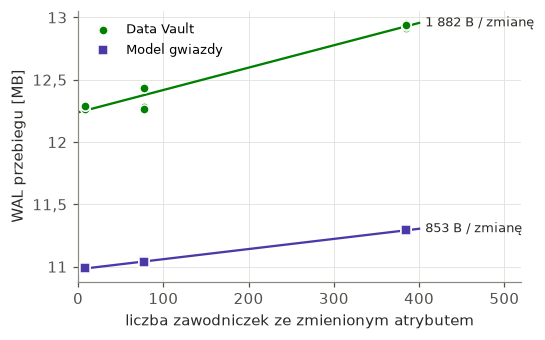

In [32]:
# Rys. 6.2 — przyrost WAL w funkcji liczby zmienionych zawodniczek
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for a in ["DV", "STAR"]:
    g = chg[chg.architecture == a]
    ax.scatter(g.zmienione, g.wal_bytes / 2**20, s=36, marker=MRK[a], color=COL[a], edgecolor="#fcfcfb",
               linewidth=1, zorder=3, label=LBL[a])
    r = stats.linregress(g.zmienione, g.wal_bytes / 2**20)
    x = np.array([0, 400])
    ax.plot(x, r.intercept + r.slope * x, color=COL[a], linewidth=1.5)
    ax.annotate(f"{r.slope * 2**20:,.0f} B / zmianę".replace(",", " "), (400, r.intercept + r.slope * 400),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5, color="#2b2a27")
ax.set_xlabel("liczba zawodniczek ze zmienionym atrybutem")
ax.set_ylabel("WAL przebiegu [MB]")
ax.yaxis.set_major_formatter(PLFMT)
ax.set_xlim(0, 520)
ax.legend(loc="upper left", fontsize=8.5)
savefig(fig, "rys_6_2_wal_zmiany")
plt.show()

## 6.3 Analiza wydajności zapytań (T8–T12)

Mediana z 5 wykonań po rozgrzewce; czas wykonania i bufory z `EXPLAIN (ANALYZE, BUFFERS)` (węzeł główny planu).

In [33]:
qm = q.groupby(["tier", "query_name", "variant"]).agg(
    exec_ms=("exec_time_ms", "median"), plan_ms=("planning_time_ms", "median"),
    blks=("shared_blks_hit", "median"), read=("shared_blks_read", "max")).reset_index()
print("bloki czytane z dysku (max):", int(qm.read.max()), "— wszystkie zapytania obsłużone z pamięci podręcznej")
w = qm.pivot_table(index=["tier", "query_name"], columns="variant", values=["exec_ms", "plan_ms", "blks"])
w.columns = [f"{a}_{b}" for a, b in w.columns]
w = w.reset_index()
w["dmart/star"] = (w.exec_ms_dmart / w.exec_ms_star).round(2)
w["dv/star"] = (w.exec_ms_dv / w.exec_ms_star).round(2)
w["bufory dv/dmart"] = (w.blks_dv / w.blks_dmart).round(2)
t9 = w.assign(tier=w.tier.map(P), zapytanie=w.query_name.map(QUERIES))
t9_p4 = t9[t9.tier == "P4"][["zapytanie", "exec_ms_star", "exec_ms_dmart", "exec_ms_dv", "dmart/star", "dv/star",
                             "plan_ms_star", "plan_ms_dv", "bufory dv/dmart"]].round(2)
t9_p4

bloki czytane z dysku (max): 0 — wszystkie zapytania obsłużone z pamięci podręcznej


,zapytanie,exec_ms_star,exec_ms_dmart,exec_ms_dv,dmart/star,dv/star,plan_ms_star,plan_ms_dv,bufory dv/dmart
0,Q1 agregacja faktów,13.05,13.42,214.11,1.03,16.41,0.16,1.53,5.17
1,Q2 turniej × nawierzchnia,21.26,20.40,175.74,0.96,8.27,0.26,1.80,5.67
2,Q3 ranking asów,113.75,113.54,230.91,1.00,2.03,0.57,2.94,3.67
3,Q4 kraj × nawierzchnia,74.52,74.17,204.38,1.00,2.74,0.36,2.72,5.50
4,Q5 bilans H2H,8.09,8.15,23.22,1.01,2.87,0.97,1.23,2.63
5,Q6 forma krocząca,53.40,53.01,36.26,0.99,0.68,0.36,4.84,4.65
6,Q7 stan na chwilę T,63.71,62.82,108.84,0.99,1.71,0.57,1.84,3.14


In [11]:
# zbiorczo dla wszystkich przekrojów: rozkład ilorazów
t9.groupby("tier")[["dmart/star", "dv/star"]].agg(["min", "median", "max"]).reindex(["P1", "P2", "P3", "P4"])

dmart/star              dv/star              
            min median   max     min median    max
tier                                              
P1         0.83   1.02  1.13    1.09   2.44  11.66
P2         0.96   0.99  1.05    0.73   2.48  13.70
P3         0.97   1.00  1.03    0.78   2.72  15.17
P4         0.96   1.00  1.03    0.68   2.74  16.41

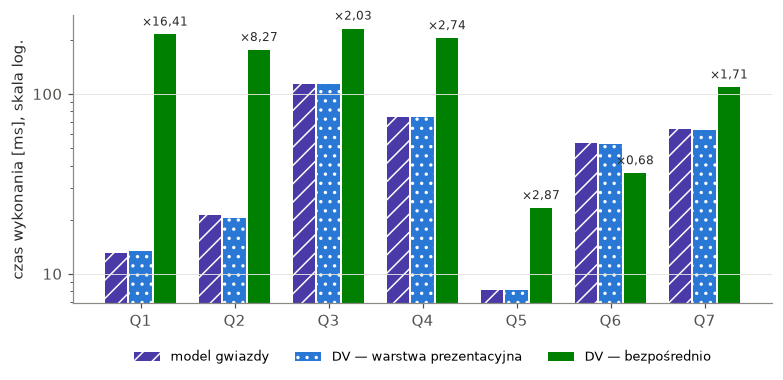

In [34]:
# Rys. 6.3 — czas zapytań na P4, trzy warianty (skala logarytmiczna)
var = [("star", "STAR"), ("dmart", "DMART"), ("dv", "DV")]
x = np.arange(len(QUERIES))
fig, ax = plt.subplots(figsize=(8.2, 3.4))
wbar = 0.26
for j, (v, key) in enumerate(var):
    vals = t9_p4[f"exec_ms_{v}"].values
    ax.bar(x + (j - 1) * wbar, vals, width=wbar - 0.02, color=COL[key], hatch=HATCH[key],
           edgecolor="#fcfcfb", linewidth=0, label={"STAR": "model gwiazdy", "DMART": "DV — warstwa prezentacyjna",
                                                   "DV": "DV — bezpośrednio"}[key])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(PLFMT)
ax.set_xticks(x, [k.split(" ")[0] for k in QUERIES.values()])
ax.set_ylabel("czas wykonania [ms], skala log.")
ax.grid(axis="x", visible=False)
for xi, r in zip(x, t9_p4["dv/star"]):
    ax.text(xi + wbar, t9_p4["exec_ms_dv"].iloc[xi] * 1.12, "×" + pl(r, 2), ha="center", fontsize=8, color="#2b2a27")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8.5)
savefig(fig, "rys_6_3_zapytania_p4")
plt.show()

## 6.4 Wpływ wielkości zbioru danych na wydajność (T13–T14)

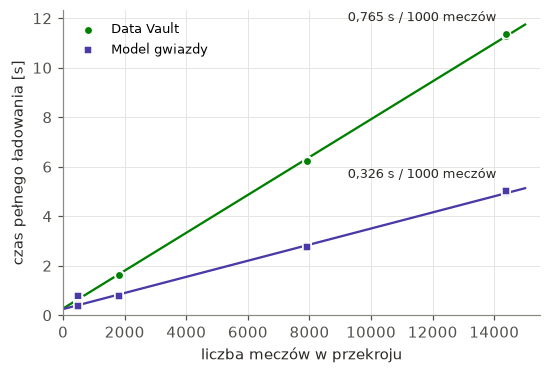

architecture,DV,STAR,DV/Star
tier,,,
P1,0.731,0.436,1.68
P2,1.624,0.787,2.06
P3,6.229,2.758,2.26
P4,11.312,4.975,2.27


In [35]:
# Rys. 6.4 — czas pełnego ładowania w funkcji liczby meczów (wszystkie powtórzenia + model afiniczny)
fig, ax = plt.subplots(figsize=(5.6, 3.6))
xs = np.linspace(0, 15000, 50)
for a in ["DV", "STAR"]:
    g = full[full.architecture == a]
    ax.scatter(g.matches, g.duration_s, s=30, marker=MRK[a], color=COL[a], edgecolor="#fcfcfb", linewidth=1,
               zorder=3, label=LBL[a])
    m = model[a]
    ax.plot(xs, m["c"] + m["k"] * xs, color=COL[a], linewidth=1.5)
    ax.annotate(pl(1000 * m["k"], 3) + " s / 1000 meczów", (14376, m["c"] + m["k"] * 14376), xytext=(-6, 10),
                textcoords="offset points", ha="right", fontsize=8.5, color="#2b2a27")
ax.set_xlabel("liczba meczów w przekroju")
ax.set_ylabel("czas pełnego ładowania [s]")
ax.yaxis.set_major_formatter(PLFMT)
ax.set_xlim(0, 15500); ax.set_ylim(0, None)
ax.legend(loc="upper left", fontsize=8.5)
savefig(fig, "rys_6_4_skalowanie_etl")
plt.show()

ratio = full.groupby(["tier", "architecture"]).duration_s.median().unstack()
ratio["DV/Star"] = (ratio.DV / ratio.STAR).round(2)
ratio.reindex(TIERS).rename(index=P)

## 6.5 Analiza wykorzystania zasobów (T15–T18)

Uwagi: proces ładowania wykonuje jeden proces serwera, dlatego obciążenie procesora (~95% jednego rdzenia)
nie różnicuje architektur — informacyjny jest czas procesora [s]. Pamięć kontenera obejmuje pamięć podręczną stron.

In [36]:
rows = []
for tier in TIERS:
    for a in ["DV", "STAR"]:
        g = full[(full.tier == tier) & (full.architecture == a)]
        rows.append({"przekrój": P[tier], "arch.": a, "CPU [s]": g.cpu_net_s.median(),
                     "CPU [%]": g.cpu_avg_pct.median(), "RAM szczyt [MB]": g.mem_peak_mb.median(),
                     "temp [MB]": g.temp_bytes.median() / 2**20, "WAL [MB]": g.wal_bytes.median() / 2**20,
                     "rozmiar [MB]": g.size_arch_mb.median(), "stg [MB]": g.size_stg_mb.median(),
                     "kB / mecz": 1024 * g.size_arch_mb.median() / g.matches.iloc[0],
                     "zapisane wiersze": int(g.rows_arch.median())})
t15 = pd.DataFrame(rows).round(2)
t15

,przekrój,arch.,CPU [s],CPU [%],RAM szczyt [MB],temp [MB],WAL [MB],rozmiar [MB],stg [MB],kB / mecz,zapisane wiersze
0,P1,DV,0.71,97.1,64.1,0.00,6.27,4.34,1.45,8.89,12959
1,P1,STAR,0.38,95.8,41.5,0.00,2.62,0.94,1.42,1.93,1961
2,P2,DV,1.54,95.0,86.6,0.00,14.91,9.40,3.13,5.30,34724
3,P2,STAR,0.76,96.2,49.6,0.00,5.53,1.85,3.10,1.04,4721
4,P3,DV,5.91,94.9,193.7,0.00,54.32,32.46,10.99,4.19,135035
5,P3,STAR,2.63,95.2,85.4,0.00,18.68,5.96,10.96,0.77,17410
6,P4,DV,10.84,95.6,321.1,27.32,95.78,57.19,19.14,4.07,239809
7,P4,STAR,4.73,95.0,121.7,10.87,32.47,10.37,19.11,0.74,30632


In [37]:
p4r = t15[t15["przekrój"] == "P4"].set_index("arch.").drop(columns="przekrój")
(p4r.loc["DV"] / p4r.loc["STAR"]).round(2).rename("DV / Star (P4)").to_frame().T

,CPU [s],CPU [%],RAM szczyt [MB],temp [MB],WAL [MB],rozmiar [MB],stg [MB],kB / mecz,zapisane wiersze
DV / Star (P4),2.29,1.01,2.64,2.51,2.95,5.51,1.0,5.5,7.83


## 6.6 Porównanie skalowalności badanych modeli (T19–T20)

Model podstawowy: **t = c + k·n** (koszt stały *c*, koszt krańcowy *k*). Model log-log *t = a·nᵇ* podano
kontrolnie — wartości b < 1 wynikają z kosztu stałego, a nie z podliniowości procesu.

In [38]:
rows = []
for a in ["DV", "STAR"]:
    m = model[a]
    g = full[full.architecture == a]
    rl = stats.linregress(np.log(g.matches), np.log(g.duration_s))
    tq = stats.t.ppf(0.975, len(g) - 2)
    mb = stats.linregress(g.matches, g.size_arch_mb)
    rows.append({"architektura": a, "c [s]": f"{m['c']:.3f} [{m['c_lo']:.3f}; {m['c_hi']:.3f}]",
                 "k [s/1000]": f"{1000*m['k']:.3f} [{1000*m['k_lo']:.3f}; {1000*m['k_hi']:.3f}]",
                 "R² afiniczny": round(m["r2"], 4), "b (log-log)": f"{rl.slope:.3f} ± {tq*rl.stderr:.3f}",
                 "MB / 1000 meczów": round(1000 * mb.slope, 3), "n obs.": m["n"]})
t19 = pd.DataFrame(rows)
display(t19)
print(f"iloraz kosztów krańcowych k_DV / k_Star = {model['DV']['k'] / model['STAR']['k']:.2f}")

,architektura,c [s],k [s/1000],R² afiniczny,b (log-log),MB / 1000 meczów,n obs.
0,DV,0.272 [0.217; 0.327],0.765 [0.758; 0.772],0.9997,0.822 ± 0.040,3.801,20
1,STAR,0.249 [0.176; 0.322],0.326 [0.317; 0.334],0.9970,0.709 ± 0.078,0.679,20


iloraz kosztów krańcowych k_DV / k_Star = 2.35


In [39]:
# elastyczność czasu zapytań względem wolumenu (log-log, 20 obserwacji na zapytanie i wariant)
rows = []
for (qn, v), g in q.groupby(["query_name", "variant"]):
    r = stats.linregress(np.log(g.volume), np.log(g.exec_time_ms))
    rows.append({"zapytanie": QUERIES[qn], "wariant": v, "b": round(r.slope, 3), "R²": round(r.rvalue**2, 3)})
pd.DataFrame(rows).pivot(index="zapytanie", columns="wariant", values="b")

wariant,dmart,dv,star
zapytanie,,,
Q1 agregacja faktów,0.998,1.038,0.920
Q2 turniej × nawierzchnia,0.958,0.995,0.969
Q3 ranking asów,1.027,1.007,1.044
Q4 kraj × nawierzchnia,0.911,0.930,0.924
Q5 bilans H2H,0.839,0.920,0.848
Q6 forma krocząca,1.086,0.963,1.067
Q7 stan na chwilę T,0.913,0.959,0.907


## 6.7 Zestawienie wyników (P4)

In [40]:
star_q = t9_p4.set_index("zapytanie")
summary = pd.DataFrame([
    ("Pełne ładowanie [s]", full[(full.tier == "mid_10y") & (full.architecture == "DV")].duration_s.median(),
     full[(full.tier == "mid_10y") & (full.architecture == "STAR")].duration_s.median()),
    ("Ładowanie warstw hurtowni [s]", g3.loc[("mid_10y", "DV"), "hurtownia razem"], g3.loc[("mid_10y", "STAR"), "hurtownia razem"]),
    ("Koszt krańcowy [s / 1000 meczów]", 1000 * model["DV"]["k"], 1000 * model["STAR"]["k"]),
    ("Ładowanie przyrostowe [s]", inc[(inc.scenario == "incremental") & (inc.architecture == "DV")].duration_s.median(),
     inc[(inc.scenario == "incremental") & (inc.architecture == "STAR")].duration_s.median()),
    ("Wiersze zapisane na zmianę atrybutu", t7m.set_index("architektura").loc["DV", "wiersze / zmiana"],
     t7m.set_index("architektura").loc["STAR", "wiersze / zmiana"]),
    ("Czas CPU [s]", p4r.loc["DV", "CPU [s]"], p4r.loc["STAR", "CPU [s]"]),
    ("Rozmiar [MB]", p4r.loc["DV", "rozmiar [MB]"], p4r.loc["STAR", "rozmiar [MB]"]),
    ("Zapytania: mediana ilorazu dmart/star", t9[t9.tier == "P4"]["dmart/star"].median(), 1.0),
], columns=["miara", "DV", "Star"])
summary["DV / Star"] = (summary.DV / summary.Star).round(2)
summary.round(3)

,miara,DV,Star,DV / Star
0,Pełne ładowanie [s],11.312,4.975,2.27
1,Ładowanie warstw hurtowni [s],7.457,1.108,6.73
2,Koszt krańcowy [s / 1000 meczów],0.765,0.326,2.35
3,Ładowanie przyrostowe [s],9.530,3.530,2.70
4,Wiersze zapisane na zmianę atrybutu,5.950,1.980,3.01
5,Czas CPU [s],10.840,4.730,2.29
6,Rozmiar [MB],57.190,10.370,5.51
7,Zapytania: mediana ilorazu dmart/star,1.000,1.000,1.00


## 7. Ocena zasadności zastosowania Data Vault — złożoność (T21) i elastyczność (T23)

In [41]:
cx["arch"] = cx.architecture.replace({"wspólne": "wspólne (stg)"})
t21 = cx.groupby(["state", "arch"])[["tables", "indexes", "views", "procedures", "code_loc"]].sum()
base = t21.loc["base"]
display(base)
print("DV / Star:", (base.loc["DV"] / base.loc["Star"]).replace(np.inf, np.nan).round(2).dropna().to_dict())
display((t21.loc["after_t23"] - base).rename_axis("przyrost po T23"))

,tables,indexes,views,procedures,code_loc
arch,,,,,
DV,32,38,7,38,3277
Star,6,12,0,7,642
wspólne (stg),25,1,18,40,2541


DV / Star: {'tables': 5.33, 'indexes': 3.17, 'procedures': 5.43, 'code_loc': 5.1}


,tables,indexes,views,procedures,code_loc
przyrost po T23,,,,,
DV,4,6,0,2,117
Star,1,2,0,1,54
wspólne (stg),2,0,0,1,36


In [20]:
t23 = ev.groupby(["phase", "step", "architecture"]).agg(
    czas_s=("duration_s", "median"), wal_mb=("wal_bytes", lambda x: x.median() / 2**20),
    nowe_wiersze=("rows_ins_new_tables", "median"), przepisane_wiersze=("rows_upd_del_existing_tables", "median"),
    nowe_obiekty=("objects_new", "median"), zmienione_obiekty=("objects_modified", "median"),
    zmienione=("modified_list", "first")).reset_index()
t23.round(3)

,phase,step,architecture,czas_s,wal_mb,nowe_wiersze,przepisane_wiersze,nowe_obiekty,zmienione_obiekty,zmienione
0,backfill,DV,DV,0.847,15.684,14451.0,14376.0,0.0,0.0,NaN
1,backfill,STAR,STAR,0.313,8.568,25.0,14376.0,0.0,0.0,NaN
2,backfill,shared,shared,0.004,0.010,50.0,0.0,0.0,0.0,NaN
3,ddl,00_stg.sql,shared,0.003,0.060,0.0,0.0,3.0,0.0,NaN
4,ddl,10_dv.sql,DV,0.012,0.062,0.0,0.0,8.0,0.0,NaN
5,ddl,20_dmart.sql,DV,0.007,0.021,0.0,0.0,4.0,2.0,procedure:dbo.sp_load_all_dv_full;table:dmart....
6,ddl,30_star.sql,STAR,0.008,0.029,0.0,0.0,4.0,2.0,procedure:star.sp_load_star_full;table:star.fc...


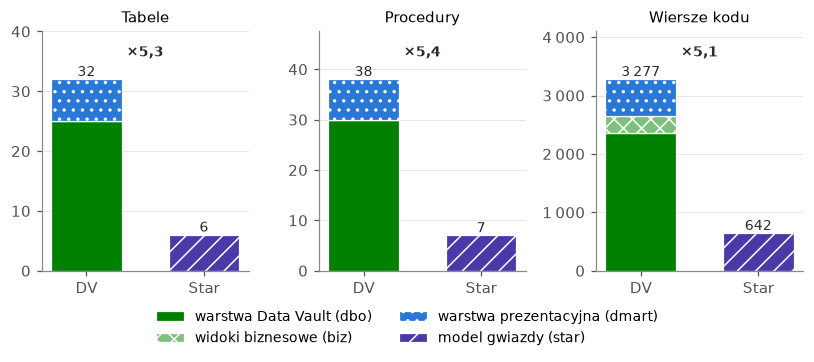

In [43]:
# --- Rys. 7.1. Złożoność implementacji w stanie bazowym (T21) ---
cx = pd.read_csv(IN / "complexity.csv")
cx = cx[cx.state == "base"].set_index("layer")

LAYERS = [  # (warstwa w CSV, etykieta, kolor, kreskowanie)
    ("dbo (Data Vault)",      "warstwa Data Vault (dbo)",      COL["DV"],    ""),
    ("biz (widoki)",          "widoki biznesowe (biz)",        "#7fbf7f",    "xx"),
    ("dmart (prezentacyjna)", "warstwa prezentacyjna (dmart)", COL["DMART"], HATCH["DMART"]),
]
STAR = ("star", "model gwiazdy (star)", COL["STAR"], HATCH["STAR"])
MEASURES = [("tables", "Tabele"), ("procedures", "Procedury"), ("code_loc", "Wiersze kodu")]
thin = lambda v: f"{int(v):,}".replace(",", "\u2009")

fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.9))
for ax, (m, title) in zip(axes, MEASURES):
    bottom = 0
    for layer, lab, c, h in LAYERS:
        v = cx.loc[layer, m]
        ax.bar(0, v, bottom=bottom, color=c, hatch=h, edgecolor="white", linewidth=0.8, width=0.6, label=lab)
        bottom += v
    dv_total = bottom
    _, lab, c, h = STAR
    st = cx.loc[STAR[0], m]
    ax.bar(1, st, color=c, hatch=h, edgecolor="white", linewidth=0.8, width=0.6, label=lab)
    for x, v in ((0, dv_total), (1, st)):
        ax.text(x, v, thin(v), ha="center", va="bottom", fontsize=9, color="#2b2a27")
    ax.text(0.5, dv_total * 1.12, "×" + pl(dv_total / st, 1), ha="center",
            fontsize=9, fontweight="bold", color="#2b2a27")
    ax.set_ylim(0, dv_total * 1.25)
    ax.set_xticks([0, 1], ["DV", "Star"])
    ax.set_title(title, fontsize=10)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: thin(v)))
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.14))
fig.tight_layout()
savefig(fig, "rys_7_1_zlozonosc")
plt.show()

In [44]:
# eksport wszystkich tabel do CSV (wejście do tabel LaTeX)
OUT = IN / "analysis"
OUT.mkdir(exist_ok=True)
for name, df in {"t1_full_load": t1, "t2_stages_p4": t2_p4, "t3_components": t3, "t4_incremental": t4,
                 "t7_changes": t7, "t7_marginal": t7m, "t9_queries": t9, "t15_resources": t15,
                 "t19_scalability": t19, "t21_complexity": t21.reset_index(), "t23_evolution": t23,
                 "summary": summary}.items():
    df.to_csv(OUT / f"{name}.csv", index=False)
print("tabele:", OUT, "| wykresy:", FIG)

tabele: ../bench_results/analysis | wykresy: ../bench_results/figures
